# Comparación de tres modelos Hugging Face para análisis de sentimientos en español

**Objetivo:** comparar calidad predictiva y eficiencia de tres modelos preentrenados para clasificar opiniones en español. **Resultados:** se generan al ejecutar el cuaderno, no están precalculados.


## 1. Ecosistema y criterios de selección
- **Models:** catálogo de modelos y fichas técnicas.
- **Datasets:** conjuntos de datos para pruebas y evaluación.
- **Spaces:** demostraciones y aplicaciones interactivas.

**Criterios:** idioma español, tarea de clasificación de sentimientos, etiquetas compatibles, disponibilidad pública, F1 macro, accuracy, latencia y memoria GPU. **Regla orientativa:** accuracy ≥ 0.80, tomada del ejemplo de T10; no constituye un resultado garantizado.

**Caso:** opiniones de productos en español. Para una comparación coherente, convertimos las estrellas 1–2 en NEG, 4–5 en POS y excluimos 3 estrellas. Este cambio define un problema binario y debe documentarse; no mide desempeño en clase neutral.

## 2. GPU e instalación

In [1]:
!nvidia-smi
import torch
print('CUDA disponible:', torch.cuda.is_available())
assert torch.cuda.is_available(), 'Activa GPU en Entorno de ejecución > Cambiar tipo de entorno de ejecución.'

Sun Oct 25 20:16:54 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   46C    P8             12W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
%pip -q install 'transformers>=4.44,<5' 'datasets>=3,<5' 'huggingface_hub>=0.25,<2' 'scikit-learn>=1.3,<2' 'pandas>=2,<3' 'matplotlib>=3.7,<4' 'pyarrow>=15'

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.30.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.41.0 requires huggingface-hub<2.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


Si Colab indica que debe reiniciarse el entorno tras instalar dependencias, reinícialo y continúa desde la siguiente celda. Para mayor reproducibilidad, registra las versiones efectivas que se muestran abajo.

In [3]:
import os, gc, time, random, platform
import numpy as np, pandas as pd, torch, transformers, datasets, sklearn
from transformers import pipeline
from datasets import load_dataset
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix
from IPython.display import display
SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
print({'python':platform.python_version(),'torch':torch.__version__,'transformers':transformers.__version__,'datasets':datasets.__version__,'sklearn':sklearn.__version__,'gpu':torch.cuda.get_device_name(0)})

{'python': '3.13.16', 'torch': '2.11.0+cu130', 'transformers': '4.57.6', 'datasets': '4.8.5', 'sklearn': '1.6.1', 'gpu': 'Tesla T4'}


## 3. Autenticación segura en Hugging Face Hub
Los modelos públicos no requieren autenticación. Si deseas autenticarte, guarda el token en **Secrets** de Colab como `HF_TOKEN`. Nunca escribas el token en el cuaderno ni lo subas a GitHub.

In [4]:
from huggingface_hub import login
try:
    from google.colab import userdata
    token=userdata.get('HF_TOKEN')
except (ImportError, KeyError, Exception):
    token=None
if token:
    login(token=token, add_to_git_credential=False)
    print('Autenticación realizada.')
else:
    print('Sin token: se utilizarán recursos públicos.')
del token

Sin token: se utilizarán recursos públicos.


## 4. Dataset y control de calidad
Dataset público: `amazon_reviews_multi`, configuración `es`, partición `test`. Se filtran valoraciones neutrales y se selecciona una muestra **balanceada y reproducible** de hasta 100 opiniones por clase. La muestra reducida es para prototipado; no representa necesariamente la distribución real de reseñas. Si falla la descarga, revisar el estado y condiciones de acceso del dataset en Hugging Face.

In [5]:
from datasets import load_dataset

dataset = load_dataset(
    "clapAI/MultiLingualSentiment",
    split="test",
    streaming=True
)

# Inspeccionar estructura
print("Columnas:", dataset.column_names)

for registro in dataset.take(3):
    print(registro)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

Columnas: ['text', 'label', 'source', 'domain', 'language']
{'text': 'i don t want to be so caught up in serving that the reason why i need to go to church is because i need to book seats or i need to serve in my ministry or because i need talk to people to make them feel welcomed in church', 'label': 'positive', 'source': 'https://huggingface.co/datasets/dair-ai/emotion', 'domain': 'emotion', 'language': 'en'}
{'text': 'Очень крутая майка,спасибо продавцу)))', 'label': 'positive', 'source': 'https://github.com/sismetanin/rureviews/blob/master/women-clothing-accessories.3-class.balanced.csv', 'domain': 'products reviews', 'language': 'ru'}
{'text': 'I ordered a PC from PCSPECIALIST, it took 24 working days for it to be built and delivered to my house, I expected some delay due to the chip shortages. Which I expected and accepted, build quality is amazing.\nOnly think I marked down for them is the communication, I expected for transparency regarding how long my gpu would of taken to be 

In [6]:
import pandas as pd
from collections import Counter

objetivo = {
    "positive": 1000,
    "neutral": 1000,
    "negative": 1000
}

registros = []
conteo = Counter()
textos_vistos = set()

for registro in dataset:
    idioma = str(registro["language"]).strip().lower()
    etiqueta = str(registro["label"]).strip().lower()
    texto = str(registro["text"]).strip()

    # Validar idioma, sentimiento y texto
    if idioma != "es":
        continue

    if etiqueta not in objetivo:
        continue

    if not texto:
        continue

    # Evitar comentarios duplicados
    clave = " ".join(texto.casefold().split())

    if clave in textos_vistos:
        continue

    if conteo[etiqueta] >= objetivo[etiqueta]:
        continue

    registros.append({
        "text": texto,
        "label": etiqueta,
        "language": idioma,
        "source": registro["source"],
        "domain": registro["domain"]
    })

    textos_vistos.add(clave)
    conteo[etiqueta] += 1

    if all(conteo[c] >= objetivo[c] for c in objetivo):
        break

df = pd.DataFrame(
    registros,
    columns=["text", "label", "language", "source", "domain"]
)

print("Distribución obtenida:")
print(df["label"].value_counts())

print("\nTotal:", len(df))
print("Idiomas:", df["language"].unique())

Distribución obtenida:
label
positive    1000
neutral     1000
negative    1000
Name: count, dtype: int64

Total: 3000
Idiomas: ['es']


In [7]:
assert len(df) == 3000, "No se obtuvieron los 3000 registros"
assert set(df["language"]) == {"es"}
assert df["label"].value_counts().eq(1000).all()

df = df.sample(frac=1, random_state=42).reset_index(drop=True)

df.to_csv(
    "comentarios_espanol_3000.csv",
    index=False,
    encoding="utf-8-sig"
)

from google.colab import files
files.download("comentarios_espanol_3000.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 5. Modelos preentrenados
Se comparan tres checkpoints de clasificación de sentimientos que admiten español. Se revisarán sus etiquetas mediante `id2label` antes de evaluar. **Nota:** algunos checkpoints son de dominio Twitter; una posible caída en reseñas de productos sería evidencia de cambio de dominio.

1. `pysentimiento/robertuito-sentiment-analysis` (español, POS/NEG/NEU).
2. `finiteautomata/beto-sentiment-analysis` (español; verificar disponibilidad y etiquetas en ejecución).
3. `cardiffnlp/twitter-xlm-roberta-base-sentiment` (multilingüe, etiquetas de sentimiento).

Los checkpoints pueden cambiar o dejar de estar disponibles: el cuaderno registra errores y exige tres evaluaciones completas para emitir una recomendación.

In [8]:
import gc
import time
import torch
import pandas as pd

from transformers import pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# ==================================================
# 1. CONFIGURACIÓN DE MODELOS
# ==================================================

modelos = {
    "BERT": "finiteautomata/beto-sentiment-analysis",
    "DistilBERT": "lxyuan/distilbert-base-multilingual-cased-sentiments-student",
    "RoBERTa": "pysentimiento/robertuito-sentiment-analysis"
}

mapa_etiquetas = {
    "NEG": "negative",
    "NEU": "neutral",
    "POS": "positive",
    "negative": "negative",
    "neutral": "neutral",
    "positive": "positive"
}

# ==================================================
# 2. VALIDACIÓN DEL DATASET
# ==================================================

assert torch.cuda.is_available(), "GPU no disponible"
assert len(df) == 3000, "Se requieren 3000 registros"

assert set(df["language"]) == {"es"}

assert df["label"].value_counts().to_dict() == {
    "positive": 1000,
    "neutral": 1000,
    "negative": 1000
}

assert df["text"].notna().all()

textos = df["text"].astype(str).tolist()
etiquetas_reales = df["label"].tolist()

print("GPU:", torch.cuda.get_device_name(0))
print("Registros:", len(textos))

# ==================================================
# 3. INFERENCIA Y EVALUACIÓN
# ==================================================

resultados = []
predicciones_modelos = {}

for nombre, modelo_id in modelos.items():

    print(f"\nEvaluando {nombre}...")

    clasificador = pipeline(
        task="text-classification",
        model=modelo_id,
        tokenizer=modelo_id,
        device=0
    )

    # Calentamiento de GPU
    clasificador(
        textos[:4],
        truncation=True,
        max_length=128,
        batch_size=4
    )

    torch.cuda.synchronize()
    inicio = time.perf_counter()

    salida = clasificador(
        textos,
        truncation=True,
        max_length=128,
        batch_size=4
    )

    torch.cuda.synchronize()
    tiempo_total = time.perf_counter() - inicio

    predicciones = [
        mapa_etiquetas[p["label"]]
        for p in salida
    ]

    predicciones_modelos[nombre] = predicciones

    resultados.append({
        "Modelo": nombre,
        "Accuracy": accuracy_score(
            etiquetas_reales, predicciones
        ),
        "Precision": precision_score(
            etiquetas_reales, predicciones,
            average="macro", zero_division=0
        ),
        "Recall": recall_score(
            etiquetas_reales, predicciones,
            average="macro", zero_division=0
        ),
        "F1-score": f1_score(
            etiquetas_reales, predicciones,
            average="macro", zero_division=0
        ),
        "Tiempo total (s)": tiempo_total,
        "Latencia (ms/texto)": (
            tiempo_total / len(textos) * 1000
        )
    })

    print(f"{nombre} finalizado en {tiempo_total:.2f} segundos")

    del clasificador
    gc.collect()
    torch.cuda.empty_cache()

# ==================================================
# 4. TABLA COMPARATIVA
# ==================================================

tabla_final = pd.DataFrame(resultados)

display(tabla_final.round(4))

# ==================================================
# 5. EXPORTACIÓN DE RESULTADOS
# ==================================================

tabla_final.to_csv(
    "resultados_comparacion_modelos.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nResultados guardados correctamente.")

GPU: Tesla T4
Registros: 3000

Evaluando BERT...


config.json:   0%|          | 0.00/841 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/440M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/528 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

...

special_tokens_map.json:   0%|          | 0.00/167 [00:00<?, ?B/s]

Device set to use cuda:0


RoBERTa finalizado en 13.42 segundos


,Modelo,Accuracy,Precision,Recall,F1-score,Tiempo total (s),Latencia (ms/texto)
0,BERT,0.6317,0.6164,0.6317,0.6158,14.0755,4.6918
1,DistilBERT,0.5507,0.5131,0.5507,0.4818,8.1053,2.7018
2,RoBERTa,0.6580,0.6407,0.6580,0.6370,13.4223,4.4741



Resultados guardados correctamente.


## 7. Tabla comparativa, gráficos y conclusiones parciales
**Criterio de decisión:** entre los modelos que alcancen accuracy ≥ 0.80, seleccionar mayor F1 macro; usar menor latencia como desempate. Si ninguno alcanza el umbral, señalar la necesidad de adaptación o fine-tuning (sin afirmar que ya se realizó). La precisión macro no es el promedio de las probabilidades del pipeline.

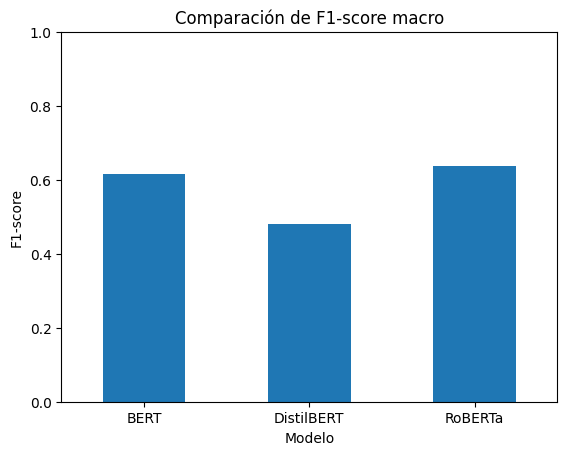

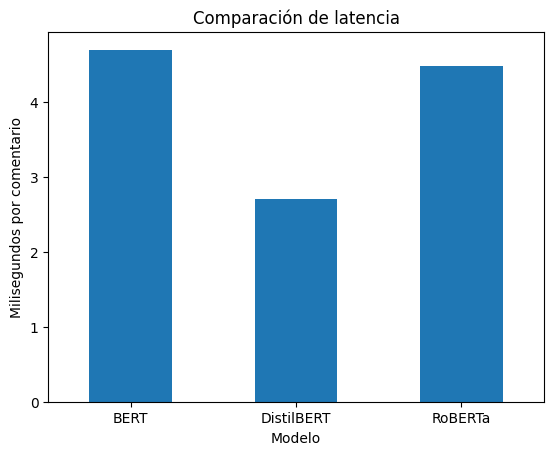

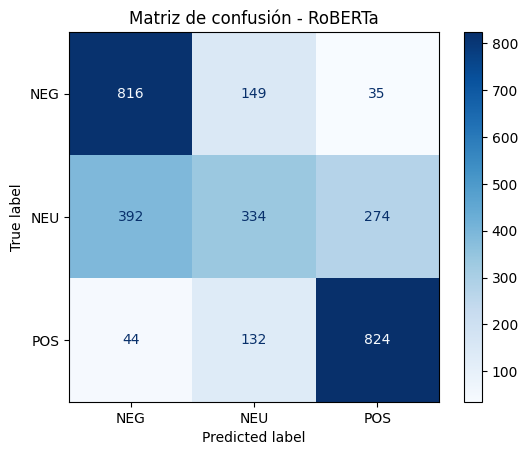

In [9]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Gráfica de F1-score
tabla_final.plot(
    x="Modelo",
    y="F1-score",
    kind="bar",
    legend=False,
    title="Comparación de F1-score macro"
)

plt.ylabel("F1-score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.show()

# Gráfica de latencia
tabla_final.plot(
    x="Modelo",
    y="Latencia (ms/texto)",
    kind="bar",
    legend=False,
    title="Comparación de latencia"
)

plt.ylabel("Milisegundos por comentario")
plt.xticks(rotation=0)
plt.show()

# Matriz de confusión del modelo seleccionado
clases = ["negative", "neutral", "positive"]

matriz = confusion_matrix(
    etiquetas_reales,
    predicciones_modelos["RoBERTa"],
    labels=clases
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=["NEG", "NEU", "POS"]
)

disp.plot(cmap="Blues")
plt.title("Matriz de confusión - RoBERTa")
plt.show()

## 8. Reproducibilidad, límites y repositorio GitHub
- Guardar este `.ipynb` en `notebooks/` y crear `README.md`, `requirements.txt`, `results/` y `.gitignore`.
- Documentar fecha, GPU, versiones, semilla, tamaño de muestra, checkpoints y resultados observados.
- No publicar tokens, reseñas privadas ni información personal.
- **Limitaciones:** muestra pequeña, exclusión de neutral, diferencia entre dominio Twitter/productos y posible variabilidad por hardware.
- **Fine-tuning:** solo si el desempeño es insuficiente; realizarlo con entrenamiento separado, nunca sobre el conjunto de prueba.




In [10]:
from pathlib import Path
Path('results').mkdir(exist_ok=True)
tabla_final.to_csv('results/comparacion_modelos.csv',index=False)
print('Guardado: results/comparacion_modelos.csv')

Guardado: results/comparacion_modelos.csv
